# 데코레이터와 컨텍스트 매니저

**이 노트북에서 할 일**

1. 함수를 받아 앞뒤에 기록을 출력하는 새 함수를 만들고, `@` 줄로 7절 함수에 붙입니다.
2. 파일을 열고 닫는 관리자를 `@contextmanager`로 만들어 with 문에서 씁니다.
3. 오류가 나도 파일이 닫히도록, 닫는 줄을 `finally` 블록으로 옮깁니다.

**준비물** — API 키 불필요. 모델 호출은 0번이고 비용은 들지 않습니다. 실행 시간은 1분 이내입니다.

이 절은 확장 경로(B)입니다. 쓰는 모듈은 Python에 들어 있는 functools와 contextlib뿐입니다.
1~8절과 같은 실습 폴더 `labs/part1/ch02-python`의 `.venv`를 커널로 고르고, 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

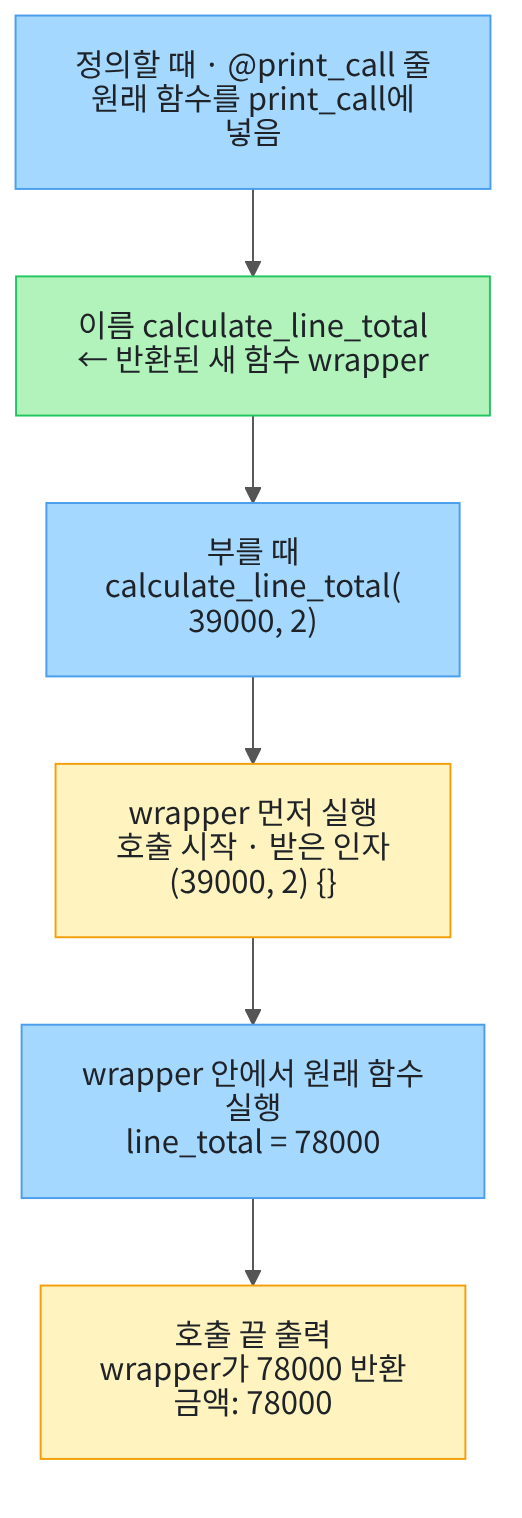

위에서 아래로 읽습니다. 파란 상자는 우리가 적은 코드, 초록 상자는 이름에 저장된 값, 노란 상자는 출력입니다.

이름 calculate_line_total로 부르면 원래 함수보다 새 함수 wrapper가 먼저 실행됩니다. 원래 함수는 wrapper 안에서 불립니다.

## 1. 준비

이 노트북은 뒤에서 주문 파일 두 개를 만듭니다. 5절·7절·8절처럼 빈 임시 폴더를 만들고, 그 폴더로 작업 위치를 옮깁니다.

In [1]:
# 파일을 둘 빈 임시 폴더를 만들고, 그 폴더로 작업 위치를 옮깁니다
import os
import tempfile

# mkdtemp()는 운영체제 임시 폴더 안에 새 폴더를 만들고 그 경로를 반환합니다
practice_folder = tempfile.mkdtemp(prefix="ch02-09-")
# chdir()는 터미널의 cd처럼 현재 작업 폴더를 옮깁니다
os.chdir(practice_folder)
file_names = os.listdir()
print("현재 작업 폴더의 파일:", file_names)

현재 작업 폴더의 파일: []


**결과 읽기** — 현재 작업 폴더의 파일은 `[]`로, 빈 폴더에서 시작합니다.
폴더의 경로는 컴퓨터마다 달라서 출력하지 않았습니다.

## 2. 함수도 값처럼 이름에 담기

먼저 7절에서 타입힌트를 적은 함수 `calculate_line_total()`을 다시 정의합니다. 정의 줄은 7절과 같습니다.
7절 노트북에서 단가 39000, 수량 2를 넣어 78000을 얻었습니다.

실행 전에 예상합니다. 정의 셀이라 출력은 없을 것입니다.

In [2]:
# 7절과 같은 타입힌트 함수를 정의합니다
def calculate_line_total(unit_price: int, quantity: int = 1) -> int:
    line_total = unit_price * quantity
    return line_total

**결과 읽기** — 예상대로 출력이 없습니다. 정의 셀은 함수를 만들어 이름에 저장만 합니다.

함수 이름 뒤에 괄호를 붙이면 함수가 실행됩니다. 괄호 없이 이름만 적으면, 실행하지 않은 함수 자체를 가리킵니다.
그래서 1절에서 숫자를 이름에 담은 것처럼, 함수도 다른 이름에 담을 수 있습니다.

7절에서 모듈 이름을 속성 `__name__`으로 읽었습니다. 함수에도 같은 속성이 있고, 정의 줄에 적은 이름이 들어 있습니다.

실행 전에 예상합니다. 새 이름 line_function으로 불러도 금액은 78000일 것입니다.

In [3]:
# 함수 이름을 괄호 없이 적어, 함수 자체를 다른 이름에 담습니다
line_function = calculate_line_total
# 속성 __name__에는 정의 줄에 적은 함수 이름이 들어 있습니다
print("담긴 함수의 이름:", line_function.__name__)
# 새 이름 뒤에 괄호와 인자를 붙이면 담긴 함수가 실행됩니다
line_total = line_function(39000, 2)
print("금액:", line_total)

담긴 함수의 이름: calculate_line_total
금액: 78000


**결과 읽기** — 담긴 함수의 이름은 `calculate_line_total`이고, 금액은 `78000`으로 예상과 같습니다.
이름 line_function과 calculate_line_total은 같은 함수를 가리킵니다. 뒤에서 이름 line_function에 담아 둔 이 원래 함수를 다시 씁니다.

## 3. 함수를 받아 새 함수를 반환하는 데코레이터

데코레이터(decorator)는 함수를 인자로 받아, 기능을 더한 새 함수를 반환하는 함수입니다.
여러 함수에 똑같이 붙일 기록 출력 같은 일을 한곳에 적어 둘 때 씁니다.

아래 함수 `print_call()`은 매개변수 function으로 함수를 받습니다. 본문에서는 함수 wrapper를 하나 더 정의합니다.
함수 안에서 정의한 wrapper가 원래 함수 대신 불릴 새 함수입니다. 새 함수 wrapper는 원래 함수를 부르기 앞뒤에 한 줄씩 출력합니다.

새 함수 wrapper의 매개변수 `*args`는 위치로 넣은 인자를 튜플 하나로 받습니다. 매개변수 `**kwargs`는 이름을 붙여 넣은 키워드 인자를 딕셔너리 하나로 받습니다.
호출 줄 `function(*args, **kwargs)`는 받은 인자를 다시 풀어 원래 함수에 그대로 넘깁니다. 그래서 인자 개수가 다른 함수에도 붙일 수 있습니다. 이 장면은 이번에 실행하지 않았습니다.

매개변수 function과 wrapper에는 타입힌트를 적지 않습니다. 함수를 가리키는 자료형 이름은 7절에서 배우지 않았습니다.
실행 전에 예상합니다. 정의 셀이라 출력은 없을 것입니다.

In [4]:
# 함수를 받아, 부르기 앞뒤에 기록을 출력하는 새 함수를 반환하는 데코레이터를 정의합니다
def print_call(function):
    # 함수 안에서 정의한 wrapper가 원래 함수 대신 불릴 새 함수입니다
    def wrapper(*args, **kwargs):
        print("호출 시작:", function.__name__)
        # args는 위치 인자의 튜플, kwargs는 키워드 인자의 딕셔너리입니다
        print("받은 인자:", args, kwargs)
        # 받은 인자를 풀어 원래 함수에 넘기고, 반환값을 받아 둡니다
        result = function(*args, **kwargs)
        print("호출 끝:", function.__name__)
        return result
    # 괄호 없이 적어, 부르지 않은 wrapper 함수 자체를 반환합니다
    return wrapper

**결과 읽기** — 예상대로 출력이 없습니다. 함수 wrapper는 print_call을 부를 때마다 새로 만들어집니다.

데코레이터 `print_call()`에 원래 함수를 괄호 없이 넣어 새 함수를 받습니다. 받은 새 함수에 이름 logged_total을 붙입니다.
그다음 logged_total에 단가 39000과 수량 2를 넣어 부릅니다.

실행 전에 예상합니다. 호출 시작과 받은 인자, 호출 끝이 출력되고 금액은 78000일 것입니다. 새 함수의 이름은 무엇일까요?

In [5]:
# 데코레이터에 원래 함수를 넣어 새 함수를 받고, 새 함수를 부릅니다
logged_total = print_call(calculate_line_total)
line_total = logged_total(39000, 2)
print("금액:", line_total)
print("새 함수의 이름:", logged_total.__name__)

호출 시작: calculate_line_total
받은 인자: (39000, 2) {}
호출 끝: calculate_line_total
금액: 78000
새 함수의 이름: wrapper


**결과 읽기** — 출력 첫 줄은 `호출 시작: calculate_line_total`, 둘째 줄은 `받은 인자: (39000, 2) {}`입니다. 이어서 `호출 끝: calculate_line_total`과 `금액: 78000`이 나왔습니다.

튜플 (39000, 2)는 위치로 넣은 두 인자이고, 빈 딕셔너리 {}는 키워드 인자가 없다는 뜻입니다.
새 함수의 이름은 `wrapper`입니다. 기록 줄에는 원래 함수 이름이 나오지만, 반환된 함수 자체는 wrapper입니다.

## 4. @ 줄로 장식하기

함수 정의 바로 위에 `@print_call`을 적으면, 정의가 끝나자마자 원래 함수가 print_call에 들어갑니다.
반환된 새 함수는 같은 이름 calculate_line_total에 저장됩니다. 줄 `calculate_line_total = print_call(calculate_line_total)`을 정의 뒤에 적는 것과 거의 같습니다.
이렇게 함수 위에 `@`와 데코레이터 이름을 적는 일을 「장식한다」고 합니다.

8절 원리 더 알아보기의 `@pytest.mark.parametrize(...)` 줄도 같은 `@` 줄입니다.
괄호 안 입력 묶음을 담은 데코레이터가 아래 테스트 함수를 받아 처리한 결과가 같은 이름에 저장됩니다.

실행 전에 예상합니다. 장식은 정의할 때 일어나지만 print_call은 출력하는 줄이 없으므로, 출력은 없을 것입니다.

In [6]:
# @ 줄로 calculate_line_total을 print_call에 넣고, 새 함수를 같은 이름에 저장합니다
@print_call
def calculate_line_total(unit_price: int, quantity: int = 1) -> int:
    line_total = unit_price * quantity
    return line_total

**결과 읽기** — 예상대로 출력이 없습니다. 이제 이름 calculate_line_total에는 장식한 새 함수가 들어 있습니다.

장식한 함수를 7절과 같은 방법으로 부릅니다. 부르는 줄에는 print_call이 보이지 않습니다.

실행 전에 예상합니다. 3번에서 본 기록 세 줄과 금액 78000이 나오고, 함수의 이름은 wrapper일 것입니다.

In [7]:
# 장식한 함수를 7절처럼 단가 39000, 수량 2로 부릅니다
line_total = calculate_line_total(39000, 2)
print("금액:", line_total)
print("함수의 이름:", calculate_line_total.__name__)

호출 시작: calculate_line_total
받은 인자: (39000, 2) {}
호출 끝: calculate_line_total
금액: 78000
함수의 이름: wrapper


**결과 읽기** — `호출 시작: calculate_line_total`부터 `금액: 78000`까지 3번과 같은 네 줄이 나왔습니다. 함수의 이름은 `wrapper`로 예상과 같습니다.

부르는 줄을 바꾸지 않고, 정의 위에 `@` 줄 하나를 더해 기록 출력이 붙었습니다.

## 5. 값 바꿔 보기 — 수량을 키워드 인자로 넣기

5절에서 매개변수 이름을 붙여 인자를 넣는 키워드 인자를 배웠습니다. 이번에는 수량을 `quantity=3`으로 넣습니다.
바꾸는 것은 호출 줄의 수량 인자 하나입니다.

실행 전에 예상합니다. 받은 인자의 튜플에는 39000만, 딕셔너리에는 quantity와 3이 들어갈 것입니다. 금액은 7절 값 바꿔 보기와 같은 117000일 것입니다.

In [8]:
# 값 바꿔 보기: 수량을 키워드 인자 quantity=3으로 넣습니다
line_total = calculate_line_total(39000, quantity=3)
print("금액:", line_total)

호출 시작: calculate_line_total
받은 인자: (39000,) {'quantity': 3}
호출 끝: calculate_line_total
금액: 117000


**결과 읽기** — 받은 인자 줄은 `받은 인자: (39000,) {'quantity': 3}`이고, 금액은 `117000`으로 예상과 같습니다.

튜플 (39000,)은 값이 하나인 튜플입니다. 키워드 인자는 딕셔너리 {'quantity': 3}에 들어갔다가, 원래 함수에 같은 이름으로 넘어갔습니다.

## 6. wraps로 원래 함수의 이름 지키기

장식한 함수의 이름이 wrapper로 바뀌면, 출력이나 오류 메시지에서 어느 함수인지 알아보기 어렵습니다.
모듈 functools의 `wraps`는 이 문제를 고치는 데코레이터입니다.

아래 셀은 3번의 print_call과 같은 정의에 `@wraps(function)` 줄 하나를 더합니다.
이 줄은 아래 wrapper 함수에 원래 함수 function의 이름 같은 정보를 복사해 붙입니다. 같은 이름 print_call로 다시 정의하므로, 앞의 정의는 덮어씁니다.
괄호가 붙은 `@wraps(function)` 줄은 원래 함수 function으로 만든 데코레이터를 씁니다. 이 데코레이터는 새 함수를 만들지 않고, 이름을 복사한 같은 wrapper를 반환합니다.

실행 전에 예상합니다. 정의 셀이라 출력은 없을 것입니다.

In [9]:
# wraps 줄을 더해, 원래 함수의 이름을 새 함수에 복사하도록 데코레이터를 다시 정의합니다
from functools import wraps


def print_call(function):
    # 이 줄은 아래 wrapper 함수에 원래 함수의 이름 같은 정보를 복사해 붙입니다
    @wraps(function)
    def wrapper(*args, **kwargs):
        print("호출 시작:", function.__name__)
        print("받은 인자:", args, kwargs)
        result = function(*args, **kwargs)
        print("호출 끝:", function.__name__)
        return result
    return wrapper

**결과 읽기** — 예상대로 출력이 없습니다. 3번의 정의와 달라진 곳은 `@wraps(function)` 줄 하나입니다.

2번에서 이름 line_function에 담아 둔 원래 함수를 새 print_call에 넣습니다. 받은 새 함수에는 이름 named_total을 붙입니다.

실행 전에 예상합니다. 기록 세 줄과 금액 78000은 3번과 같고, 새 함수의 이름만 calculate_line_total로 바뀔 것입니다.

In [10]:
# 원래 함수를 wraps를 쓴 데코레이터에 넣고, 새 함수의 이름을 확인합니다
named_total = print_call(line_function)
line_total = named_total(39000, 2)
print("금액:", line_total)
print("새 함수의 이름:", named_total.__name__)

호출 시작: calculate_line_total
받은 인자: (39000, 2) {}
호출 끝: calculate_line_total
금액: 78000
새 함수의 이름: calculate_line_total


**결과 읽기** — 기록 세 줄과 `금액: 78000`은 3번과 같습니다. 새 함수의 이름은 `calculate_line_total`로, 3번의 wrapper에서 바뀌었습니다.

함수는 여전히 wrapper가 먼저 실행되는 새 함수입니다. 바뀐 것은 이름 같은 함수 정보뿐입니다.

## 7. 파일을 열고 닫는 관리자 만들기

5절에서 `with open(...) as file:` 블록이 끝나면 파일이 닫혔습니다. 이번에는 이 규칙을 가진 함수를 직접 만듭니다.
먼저 5절과 같은 주문 파일 두 개를 만듭니다. 파일 bad_orders.txt는 첫 줄 수량이 정수로 바꿀 수 없는 글자 '많이'입니다.

실행 전에 예상합니다. 현재 작업 폴더에 파일 두 개가 보이고, 5절처럼 파일은 닫혀 있을 것입니다.

In [11]:
# 5절과 같은 주문 파일 두 개를 만듭니다(bad_orders.txt는 첫 줄 수량이 '많이')
with open("orders.txt", "w", encoding="utf-8") as file:
    file.write("연필,3\n노트,2\n")
with open("bad_orders.txt", "w", encoding="utf-8") as file:
    file.write("연필,많이\n노트,2\n")
# listdir()는 순서를 정하지 않고 반환하므로 sorted()로 이름 순서로 정렬합니다
file_names = sorted(os.listdir())
print("현재 작업 폴더의 파일:", file_names)
print("마지막 파일이 닫혔나요?", file.closed)

현재 작업 폴더의 파일: ['bad_orders.txt', 'orders.txt']
마지막 파일이 닫혔나요? True


**결과 읽기** — 현재 작업 폴더의 파일은 `['bad_orders.txt', 'orders.txt']`이고, 마지막 파일이 닫혔나요? 줄은 `True`입니다.
5절처럼 with 블록이 끝나자 파일이 닫혔습니다.

컨텍스트 매니저(context manager)는 with 블록에 들어갈 때 준비하고, 나올 때 정리하는 규칙을 가진 값입니다. 줄여서 관리자라고 부르겠습니다.
모듈 contextlib의 `contextmanager`는 함수 하나로 관리자를 만들게 해 주는 데코레이터입니다.

줄 `@contextmanager`는 아래 함수를 with 문에서 쓸 수 있는 함수로 바꿔 같은 이름에 저장합니다. 4번에서 배운 `@` 줄과 같은 규칙입니다.
함수 본문의 `yield` 줄은 값을 with 블록에 건네고, 블록이 끝날 때까지 그 자리에서 멈춥니다. 블록이 끝나면 멈춘 자리 다음 줄부터 이어서 실행합니다.

그래서 yield 줄 위에는 준비하는 줄을, 아래에는 정리하는 줄을 적습니다. 매개변수에는 7절처럼 `file_name: str`을 적습니다.
실행 전에 예상합니다. 정의 셀이라 출력은 없을 것입니다.

In [12]:
# 파일을 열어 with 블록에 건네고, 블록이 끝나면 닫는 관리자 함수를 정의합니다
from contextlib import contextmanager


# 이 줄은 아래 함수를 with 문에서 쓸 수 있는 함수로 바꿔 같은 이름에 저장합니다
@contextmanager
def open_order_file(file_name: str):
    order_file = open(file_name, "r", encoding="utf-8")
    print("파일을 열었습니다:", file_name)
    # 파일을 with 블록에 건네고, 블록이 끝날 때까지 여기서 멈춥니다
    yield order_file
    order_file.close()
    print("파일을 닫았습니다:", file_name)

**결과 읽기** — 예상대로 출력이 없습니다. 함수 본문은 with 문에서 쓸 때 실행됩니다.

관리자로 orders.txt를 열어 줄 목록을 읽습니다. yield 줄이 건넨 파일은 with 줄의 `as` 뒤 이름 order_file에 들어갑니다.
블록 안과 블록 밖에서 파일이 닫혔는지 한 번씩 출력합니다.

실행 전에 예상합니다. 블록 안에서는 닫히지 않았고, 파일을 닫았습니다 줄이 나온 뒤 블록 밖에서는 닫혔을 것입니다.

In [13]:
# 관리자로 orders.txt를 열어 줄 목록을 읽고, 블록 안과 밖에서 닫혔는지 봅니다
with open_order_file("orders.txt") as order_file:
    lines = order_file.read().splitlines()
    print("읽은 줄:", lines)
    print("블록 안에서 닫혔나요?", order_file.closed)
print("블록 밖에서 닫혔나요?", order_file.closed)

파일을 열었습니다: orders.txt
읽은 줄: ['연필,3', '노트,2']
블록 안에서 닫혔나요? False
파일을 닫았습니다: orders.txt
블록 밖에서 닫혔나요? True


**결과 읽기** — 출력 순서는 `파일을 열었습니다: orders.txt`, `읽은 줄: ['연필,3', '노트,2']`, `블록 안에서 닫혔나요? False`입니다. 그다음 `파일을 닫았습니다: orders.txt`와 `블록 밖에서 닫혔나요? True`가 나왔습니다.

관리자의 준비 줄이 먼저, 블록의 줄이 가운데, yield 아래 정리 줄이 마지막에 실행되었습니다. 5절 `with open()`과 같은 결과입니다.

## 8. Before — 블록에서 오류가 나면 닫는 줄까지 가지 못함

같은 관리자로 bad_orders.txt를 열고, 첫 줄의 수량 글자를 `int()`로 바꿉니다. 5절에서 본 것처럼 글자 '많이'는 정수로 바꿀 수 없어 `ValueError`가 납니다.
오류를 관찰하려고 5절처럼 `try`와 `except ValueError`로 감쌉니다. 마지막 줄은 try 블록 밖에서 파일이 닫혔는지 출력합니다.

실행 전에 예상해 봅니다. 오류 메시지가 나올 것입니다. 관리자의 yield 아래 닫는 줄도 실행될까요?

In [14]:
# 같은 관리자로 bad_orders.txt를 열고, 첫 줄의 수량 글자를 정수로 바꿉니다
try:
    with open_order_file("bad_orders.txt") as order_file:
        lines = order_file.read().splitlines()
        name, count_text = lines[0].split(",")
        # 수량 글자가 '많이'라서 이 줄에서 ValueError가 납니다
        count = int(count_text)
        print("첫 줄 수량:", count)
except ValueError as error:
    print("오류 메시지:", error)
print("파일이 닫혔나요?", order_file.closed)

파일을 열었습니다: bad_orders.txt
오류 메시지: invalid literal for int() with base 10: '많이'
파일이 닫혔나요? False


**결과 읽기** — 출력은 `파일을 열었습니다: bad_orders.txt`, `오류 메시지: invalid literal for int() with base 10: '많이'`, `파일이 닫혔나요? False` 세 줄입니다.
파일을 닫았습니다 줄은 나오지 않았고, 파일은 열린 채 남았습니다.

Python 문서는 with 블록에서 난 오류가 관리자 함수의 yield 자리에서 다시 일어난다고 설명합니다.
그래서 관리자 함수도 yield 줄에서 멈추고, 아래의 닫는 두 줄을 건너뛰었습니다. 오류는 셀의 `except` 블록까지 전해졌습니다.

## 9. After — finally 블록에서 닫기

`finally` 블록은 `try` 블록 뒤에 붙이는 블록입니다. try 블록이 끝나는 방법과 관계없이 마지막에 실행됩니다. 오류로 멈춰도, 오류 없이 끝나도 실행됩니다.

Before 셀과 달라진 곳은 관리자 함수 한 곳입니다. yield 줄을 try 블록에 넣고, 닫는 두 줄을 finally 블록으로 옮깁니다.
여기에는 `except` 블록이 없으므로 오류는 잡지 않고 그대로 셀에 전해집니다. 같은 이름 open_order_file로 다시 정의합니다.

실행 전에 예상합니다. 정의 셀이라 출력은 없을 것입니다.

In [15]:
# yield 줄을 try 블록에 넣고, 닫는 두 줄을 finally 블록으로 옮겨 관리자를 다시 정의합니다
@contextmanager
def open_order_file(file_name: str):
    order_file = open(file_name, "r", encoding="utf-8")
    print("파일을 열었습니다:", file_name)
    try:
        yield order_file
    # finally 블록은 with 블록이 오류로 끝나도 실행됩니다
    finally:
        order_file.close()
        print("파일을 닫았습니다:", file_name)

**결과 읽기** — 예상대로 출력이 없습니다. 준비하는 두 줄과 파일, 오류가 나는 줄은 Before와 같습니다.

Before 셀과 같은 파일, 같은 줄로 다시 실행합니다. 셀 끝에 파일이 닫혔는지 확인하는 `assert` 줄을 더합니다.

실행 전에 예상합니다. 이번에는 파일을 닫았습니다 줄이 나오고, 파일이 닫혔나요? 줄은 True일 것입니다. 오류 메시지와 어느 줄이 먼저 나올까요?

In [16]:
# Before 셀과 같은 파일, 같은 줄로 고친 관리자를 다시 씁니다
try:
    with open_order_file("bad_orders.txt") as order_file:
        lines = order_file.read().splitlines()
        name, count_text = lines[0].split(",")
        count = int(count_text)
        print("첫 줄 수량:", count)
except ValueError as error:
    print("오류 메시지:", error)
print("파일이 닫혔나요?", order_file.closed)
# 파일이 닫히지 않았으면 이 줄에서 멈춥니다
assert order_file.closed

파일을 열었습니다: bad_orders.txt
파일을 닫았습니다: bad_orders.txt
오류 메시지: invalid literal for int() with base 10: '많이'
파일이 닫혔나요? True


**결과 읽기** — 출력은 `파일을 열었습니다: bad_orders.txt`, `파일을 닫았습니다: bad_orders.txt`, `오류 메시지: invalid literal for int() with base 10: '많이'`, `파일이 닫혔나요? True` 네 줄입니다. 검사 줄 `assert`에서도 멈추지 않았습니다.

파일을 닫았습니다 줄이 오류 메시지보다 먼저 나왔습니다. 오류가 셀의 except 블록에 닿기 전에, 관리자 안의 finally 블록이 먼저 실행되었습니다.
오류는 사라지지 않았고 같은 메시지가 나왔습니다. 달라진 것은 파일이 닫혔다는 것입니다.

이번에 확인한 오류는 수량 글자 '많이'에서 난 ValueError 한 가지입니다. 파일이 없어 open() 줄에서 오류가 나는 경우는 실행하지 않았습니다.

### 원리 더 알아보기 — with 문이 부르는 두 메서드

Python 문서는 with 문이 관리자의 특별한 메서드 두 개를 부른다고 설명합니다. 블록에 들어갈 때 `__enter__`, 나올 때 `__exit__`입니다.
6절의 `__init__`처럼 밑줄 두 개로 둘러싼 이름입니다. 이 셀은 두 이름이 있는지 확인하는 함수 `hasattr()`을 씁니다. 지금은 출력만 읽습니다.

In [17]:
# 원리 더 알아보기: with 문이 부르는 두 메서드가 open() 파일과 우리 관리자에 있는지 봅니다
plain_file = open("orders.txt", "r", encoding="utf-8")
print("open() 파일의 __enter__:", hasattr(plain_file, "__enter__"))
print("open() 파일의 __exit__:", hasattr(plain_file, "__exit__"))
plain_file.close()
# 관리자 함수를 with 문 없이 부르기만 합니다
manager = open_order_file("orders.txt")
print("관리자의 __enter__:", hasattr(manager, "__enter__"))
print("관리자의 __exit__:", hasattr(manager, "__exit__"))

open() 파일의 __enter__: True
open() 파일의 __exit__: True
관리자의 __enter__: True
관리자의 __exit__: True


**결과 읽기** — 네 줄 모두 `True`입니다. 5절 open() 파일과 우리가 만든 관리자 모두 with 문이 부를 두 메서드를 가지고 있습니다.
관리자 함수를 부르기만 했을 때는 파일을 열었습니다 줄이 나오지 않았습니다. 함수 본문은 with 문이 `__enter__`를 부를 때 실행을 시작합니다.

## 정리

- 데코레이터는 함수를 받아 새 함수를 반환합니다. 정의 위의 `@print_call`은 원래 함수를 넣고 반환된 wrapper를 같은 이름에 저장합니다.
- `@wraps(function)` 한 줄로 새 함수의 이름이 wrapper에서 calculate_line_total로 바뀌었습니다.
- 관리자의 yield 아래에 둔 닫는 줄은 블록에서 오류가 나자 실행되지 않아 False가 나왔습니다. 닫는 줄을 finally 블록으로 옮기자 True가 되었습니다.

확장 경로(B)는 10절 Pydantic으로, 기본 경로(A)는 12절 async와 await로 이어집니다.